<a href="https://colab.research.google.com/github/marioschristofi14-byte/RNN/blob/main/Copy_of_RNN_2_IMDb_Workshop_runed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1)Εγκατάσταση βιβλιοθηκών

In [38]:
# Εγκατάσταση της βιβλιοθήκης datasets του Hugging Face
# Η βιβλιοθήκη μάς επιτρέπει να φορτώσουμε τις κριτικές ταινιών
!pip install -q datasets

2)Εισαγωγή βιβλιοθηκών

In [39]:
# Εισαγωγή απαραίτητων βιβλιοθηκών
import re
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from collections import Counter
from datasets import load_dataset
from torch.utils.data import DataLoader, TensorDataset

# Καθορισμός τυχαίων τιμών για επαναληψιμότητα
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Επιλογή GPU εάν είναι διαθέσιμη
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Συσκευή:", device)

Συσκευή: cpu


3)Φόρτωση IMDb Dataset

In [40]:
# Φόρτωση του IMDb Dataset
dataset = load_dataset("stanfordnlp/imdb")

# Εμφάνιση των δεδομένων
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


4)Εμφάνιση μιας κριτικής

In [41]:
# Επιλογή της πρώτης κριτικής
review = dataset["train"][0]["text"]

# Εμφάνιση κειμένου
print(review)

# Εμφάνιση χαρακτηρισμού
print("Label:", dataset["train"][0]["label"])

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, eve

5)Tokenization

In [42]:
# Δημιουργία συνάρτησης διαχωρισμού κειμένου σε λέξεις
def tokenize(text):

    # Μετατροπή κεφαλαίων σε μικρά
    text = text.lower()

    # Αφαίρεση συμβόλων αλλαγής γραμμής HTML
    text = re.sub(r"<br\s*/?>", " ", text)

    # Εντοπισμός αγγλικών λέξεων
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", text)

    return words

# Δοκιμή της συνάρτησης
print(tokenize("This Movie Was AMAZING!"))

print(tokenize(dataset["train"][0]["text"]))

['this', 'movie', 'was', 'amazing']
['i', 'rented', 'i', 'am', 'curious', 'yellow', 'from', 'my', 'video', 'store', 'because', 'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first', 'released', 'in', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized', 'by', 'u', 's', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore', 'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to', 'see', 'this', 'for', 'myself', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young', 'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything', 'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her', 'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average', 'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam', 'war', 'and', 'race', 'issues',

6)Μέτρηση συχνότητας λέξεων

In [43]:
# Δημιουργία μετρητή λέξεων
word_counts = Counter()

# Επεξεργασία των 25.000 κριτικών εκπαίδευσης
for review in dataset["train"]["text"]:

    # Μέτρηση συχνότητας κάθε λέξης
    word_counts.update(tokenize(review))

# Εμφάνιση των 10 συχνότερων λέξεων
print(word_counts.most_common(10))

[('the', 336757), ('and', 164142), ('a', 163161), ('of', 145865), ('to', 135717), ('is', 107337), ('in', 93977), ('it', 79168), ('i', 77262), ('this', 76004)]


7)Δημιουργία Vocabulary

In [44]:
# Μέγιστο μέγεθος λεξιλογίου
vocab_size = 10000

# Δημιουργία λεξιλογίου με ειδικές τιμές
vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

# Επιλογή των 9.998 συχνότερων λέξεων
most_common_words = word_counts.most_common(vocab_size - 2)

# Αντιστοίχιση κάθε λέξης σε μοναδικό αριθμό
for word, count in most_common_words:
    vocab[word] = len(vocab)

# Εμφάνιση μεγέθους λεξιλογίου
print("Vocabulary size:", len(vocab))

# Δοκιμή αντιστοίχισης
print("good:", vocab.get("good"))
print("excellent:", vocab.get("excellent"))

Vocabulary size: 10000
good: 49
excellent: 317


8)Μετατροπή λέξεων σε αριθμούς

In [45]:
# Δημιουργία συνάρτησης κωδικοποίησης
def encode_review(text):

    # Διαχωρισμός κειμένου σε λέξεις
    words = tokenize(text)

    # Μετατροπή λέξεων σε αριθμούς
    encoded = [vocab.get(word, 1) for word in words]

    return encoded

# Δοκιμή
print(encode_review("good movie"))

[49, 17]


9) Padding και Truncation

In [46]:
 # Μέγιστο μήκος κάθε κριτικής
max_length = 200

# Δημιουργία συνάρτησης Padding
def pad_review(encoded_review):

    # Διατήρηση των πρώτων 200 λέξεων
    encoded_review = encoded_review[:max_length]

    # Υπολογισμός αριθμού μηδενικών
    padding_length = max_length - len(encoded_review)

    # Προσθήκη μηδενικών
    padded_review = encoded_review + [0] * padding_length

    return padded_review

# Δοκιμή
example = pad_review(encode_review("good movie"))

print("Πρώτες 10 θέσεις:", example[:10])
print("Συνολικό μήκος:", len(example))

Πρώτες 10 θέσεις: [49, 17, 0, 0, 0, 0, 0, 0, 0, 0]
Συνολικό μήκος: 200


10)Προετοιμασία Train, Test και unsupervised δεδομένων

In [47]:
# Μετατροπή όλων των κριτικών σε διανύσματα σταθερού μήκους

# και των ετικετών σε αριθμούς κινητής υποδιαστολής

X_train = torch.tensor(
  [pad_review(encode_review(text)) for text in dataset["train"]["text"]],
  dtype=torch.long)

y_train = torch.tensor(dataset["train"]["label"], dtype=torch.float32)



X_test = torch.tensor(

    [pad_review(encode_review(text)) for text in dataset["test"]["text"]],

    dtype=torch.long

)

y_test = torch.tensor(dataset["test"]["label"], dtype=torch.float32)



# Χωρίζουμε τα δεδομένα εκπαίδευσης σε 80% Training και 20% Validation

total = len(X_train)

split = int(total * 0.8)



# Ανακατεύουμε τις θέσεις των δεδομένων

indices = torch.randperm(total)



train_indices = indices[:split]

val_indices = indices[split:]



# Δημιουργούμε τα δύο σύνολα

X_val = X_train[val_indices]

y_val = y_train[val_indices]



X_train = X_train[train_indices]

y_train = y_train[train_indices]



# Δημιουργούμε DataLoader για το Validation

val_loader = DataLoader(

    TensorDataset(X_val, y_val),

    batch_size=64,

    shuffle=False

)

11)Δημιουργία DataLoaders

In [48]:
# Αριθμός κριτικών ανά ομάδα
batch_size = 64

# Δημιουργία ομάδων εκπαίδευσης
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=batch_size,
    shuffle=True
)

# Δημιουργία ομάδων ελέγχου
test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=batch_size,
    shuffle=False
)

print("Οι DataLoaders είναι έτοιμοι!")

Οι DataLoaders είναι έτοιμοι!


12)Δημιουργία του νευρωνικού δικτύου

In [49]:
# Δημιουργία της κλάσης του RNN
class SentimentRNN(nn.Module):

    # Αρχικοποίηση των επιπέδων
    def __init__(self, vocab_size, embedding_dim, hidden_dim):

        super().__init__()

        # Μετατροπή λέξεων σε διανύσματα
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        # Δημιουργία απλού RNN
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Τελικό επίπεδο ταξινόμησης
        self.fc = nn.Linear(hidden_dim, 1)

    # Καθορισμός ροής δεδομένων
    def forward(self, x):

        # Υπολογισμός πραγματικού μήκους κάθε κριτικής
        lengths = (x != 0).sum(dim=1).clamp(min=1)

        # Μετατροπή λέξεων σε διανύσματα
        embedded = self.embedding(x)

        # Παράλειψη των θέσεων Padding
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Επεξεργασία από το RNN
        output, hidden = self.rnn(packed)

        # Υπολογισμός πρόβλεψης
        prediction = self.fc(hidden[-1])

        return prediction.squeeze(1)


# Καθορισμός παραμέτρων
embedding_dim = 64
hidden_dim = 128

# Δημιουργία μοντέλου
model = SentimentRNN(
    vocab_size,
    embedding_dim,
    hidden_dim
).to(device)

# Εμφάνιση αρχιτεκτονικής
print(model)

SentimentRNN(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (rnn): RNN(64, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


13)Εκπαίδευση και επιλογή καλύτερων βάρων

In [55]:

import copy
import matplotlib.pyplot as plt

num_runs = 1
epochs = 25

best_accuracy = -1.0
best_weights = None
best_run = None
run_results = []

for run in range(num_runs):

    print(f"\n===== RUN {run + 1}/{num_runs} =====")

    torch.manual_seed(42 + run)

    model = SentimentRNN(
        vocab_size, embedding_dim, hidden_dim
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

    run_best_accuracy = -1.0

    # Λίστες για τη γραφική
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # TRAINING
        model.train()

        total_loss = 0.0
        train_correct = 0
        train_total = 0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0)

            optimizer.step()

            total_loss += loss.item()

            # Υπολογισμός Training Accuracy
            probabilities = torch.sigmoid(outputs.detach())
            predictions = (probabilities >= 0.5).float()

            train_correct += (predictions == batch_y).sum().item()
            train_total += batch_y.size(0)

        # Τέλος του loop των Batches
        train_accuracy = 100 * train_correct / train_total
        train_accuracies.append(train_accuracy)

        # VALIDATION
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for batch_X, batch_y in val_loader:

                batch_X = batch_X.to(device)
                batch_y = batch_y.to(device)

                outputs = model(batch_X)

                probabilities = torch.sigmoid(outputs)
                predictions = (probabilities >= 0.5).float()

                correct += (predictions == batch_y).sum().item()
                total += batch_y.size(0)

        accuracy = 100 * correct / total
        val_accuracies.append(accuracy)

        average_loss = total_loss / len(train_loader)


        print(f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {average_loss:.4f} | "
            f"Training Accuracy: {train_accuracy:.2f}% | "
            f"Validation Accuracy: {accuracy:.2f}%")

        # Καλύτερο Accuracy του συγκεκριμένου Run
        if accuracy > run_best_accuracy:
            run_best_accuracy = accuracy

        # Καλύτερο Accuracy από όλα τα Runs
        if accuracy > best_accuracy:

            best_accuracy = accuracy
            best_run = run + 1
            best_weights = copy.deepcopy(model.state_dict())

            torch.save(best_weights, "best_sentiment_rnn.pth")

    run_results.append(run_best_accuracy)

    print(
        f"\nΚαλύτερη ακρίβεια Run {run + 1}: "
        f"{run_best_accuracy:.2f}%"
    )


# FINAL RESULTS

model.load_state_dict(best_weights)
model.eval()

print("\nΤΕΛΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ")
print("Καλύτερο Run:", best_run)
print(f"Καλύτερο Validation Accuracy: {best_accuracy:.2f}%")
print("Τα καλύτερα βάρη αποθηκεύτηκαν στο best_sentiment_rnn.pth")




===== RUN 1/1 =====
Epoch 1/25 | Loss: 0.6838 | Training Accuracy: 55.34% | Validation Accuracy: 60.94%
Epoch 2/25 | Loss: 0.6412 | Training Accuracy: 64.08% | Validation Accuracy: 63.80%
Epoch 3/25 | Loss: 0.6067 | Training Accuracy: 68.11% | Validation Accuracy: 66.66%
Epoch 4/25 | Loss: 0.5757 | Training Accuracy: 71.33% | Validation Accuracy: 68.38%
Epoch 5/25 | Loss: 0.5464 | Training Accuracy: 73.78% | Validation Accuracy: 70.16%
Epoch 6/25 | Loss: 0.5195 | Training Accuracy: 75.78% | Validation Accuracy: 71.48%
Epoch 7/25 | Loss: 0.4921 | Training Accuracy: 77.62% | Validation Accuracy: 74.98%
Epoch 8/25 | Loss: 0.4675 | Training Accuracy: 79.27% | Validation Accuracy: 73.88%
Epoch 9/25 | Loss: 0.4591 | Training Accuracy: 79.89% | Validation Accuracy: 76.56%
Epoch 10/25 | Loss: 0.4298 | Training Accuracy: 81.61% | Validation Accuracy: 76.04%
Epoch 11/25 | Loss: 0.4180 | Training Accuracy: 82.28% | Validation Accuracy: 77.34%
Epoch 12/25 | Loss: 0.3956 | Training Accuracy: 83.53

14)Αξιολόγηση στο σύνολο ελέγχου (Test Accuracy)

In [57]:
# Απενεργοποίηση λειτουργίας εκπαίδευσης
model.eval()

# Μετρητές σωστών και συνολικών προβλέψεων
correct = 0
total = 0

# Απενεργοποίηση υπολογισμού παραγώγων
with torch.no_grad():

    # Επεξεργασία των δεδομένων ελέγχου
    for batch_X, batch_y in test_loader:

        # Μεταφορά δεδομένων στη συσκευή
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Υπολογισμός προβλέψεων
        outputs = model(batch_X)

        # Μετατροπή σε πιθανότητες
        probabilities = torch.sigmoid(outputs)

        # Ταξινόμηση σε 0 ή 1
        predictions = (probabilities >= 0.5).float()

        # Μέτρηση σωστών προβλέψεων
        correct += (predictions == batch_y).sum().item()

        # Μέτρηση συνολικών κριτικών
        total += batch_y.size(0)

# Υπολογισμός ακρίβειας
accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 78.36%


15)Overfitting Detection

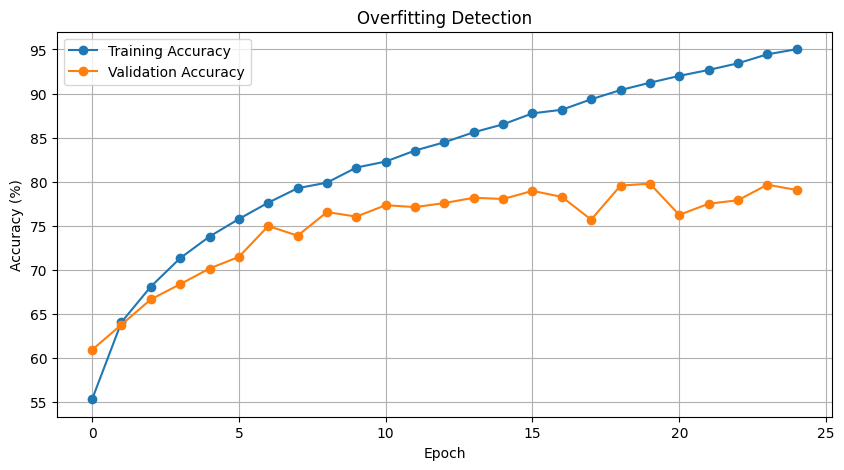

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label="Training Accuracy", marker="o")
plt.plot(val_accuracies, label="Validation Accuracy", marker="o")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Overfitting Detection")
plt.legend()
plt.grid(True)
plt.show()

16)Αξιολόγηση κριτικής από το unsupervised

In [59]:
#— Ανάλυση συγκεκριμένης IMDb Unsupervised κριτικής

# Επιλέγουμε τον αριθμό της κριτικής, όπως στο Κελί 4
index = 20

# Διαβάζουμε την κριτική από το IMDb
review = dataset["unsupervised"][index]["text"]

# Εμφανίζουμε την κριτική
print("IMDb Review:")
print(review)

# Μετατρέπουμε την κριτική σε αριθμούς
encoded = encode_review(review)

# Προσαρμόζουμε το μήκος της κριτικής
padded = pad_review(encoded)

# Μετατροπή σε Tensor
X_new = torch.tensor([padded], dtype=torch.long).to(device)

# Χρησιμοποιούμε το εκπαιδευμένο RNN
model.eval()

# Πρόβλεψη συναισθήματος
with torch.no_grad():
    output = model(X_new)
    probability = torch.sigmoid(output).item()

# Εμφάνιση αποτελέσματος
print("\n" + "=" * 50)

if probability >= 0.5:
    print("Prediction: POSITIVE")
    print(f"Positive Score: {probability * 100:.2f}%")
else:
    print("Prediction: NEGATIVE")
    print(f"Negative Score: {(1 - probability) * 100:.2f}%")

IMDb Review:
The movie is a bit sloppy from a technical standpoint, but it remains the only movie to make me literally laugh myself sick. The Farrelly brothers owe a huge debt to Robert Klane's mining of the twisted humor genre. For years, this was my video holy grail. Finally, it occurred to me that it probably showed up from time to time on the Fox Movie Channel; so, not having it on my cable system, I started buying the monthly satellite programming guides, and when it came up in the rotation on FMC, I had a friend tape it for me. A simple DVD release will not be adequate. This needs the full Special Edition treatment. And oh, how I hope there are outtakes.

Prediction: POSITIVE
Positive Score: 50.73%


17) Πρόβλεψη νέας κριτικής

In [61]:
# Δημιουργία συνάρτησης πρόβλεψης
def predict_sentiment(text):

    # Έλεγχος για κενή κριτική
    if not tokenize(text):
        print("Παρακαλώ γράψε μια κριτική στα αγγλικά.")
        return

    # Μετατροπή κριτικής σε αριθμούς
    encoded = encode_review(text)

    # Εφαρμογή Padding
    padded = pad_review(encoded)

    # Μετατροπή σε Tensor
    input_tensor = torch.tensor(
        [padded],
        dtype=torch.long
    ).to(device)

    # Απενεργοποίηση λειτουργίας εκπαίδευσης
    model.eval()

    # Υπολογισμός πρόβλεψης
    with torch.no_grad():

        output = model(input_tensor)

        # Υπολογισμός πιθανότητας θετικής κριτικής
        positive_probability = torch.sigmoid(output).item()

    # Υπολογισμός πιθανότητας αρνητικής κριτικής
    negative_probability = 1 - positive_probability

    # Εμφάνιση κριτικής
    print("\nReview:", text)

    # Εμφάνιση χαρακτηρισμού
    if positive_probability >= 0.5:
        print("Prediction: Positive Review")
    else:
        print("Prediction: Negative Review")

    # Εμφάνιση πιθανοτήτων
    print(f"Positive probability: {positive_probability*100:.2f}%")
    print(f"Negative probability: {negative_probability*100:.2f}%")


# Εισαγωγή κριτικής από τον χρήστη
review = input("Write your movie review: ")

# Εμφάνιση πρόβλεψης
predict_sentiment(review)

Write your movie review: just the right omound of sex

Review: just the right omound of sex
Prediction: Negative Review
Positive probability: 48.11%
Negative probability: 51.89%
